In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import shutil
import glob
import logging
import xml.etree.ElementTree as ET

from pathlib import Path
from io import StringIO
from typing import Dict, List, Optional, Union
from functools import reduce
import multiprocess as mp
from multiprocessing import cpu_count

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from tqdm.contrib.logging import logging_redirect_tqdm
import logging

import parmed
from openbabel import openbabel

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

from plip.structure.preparation import PDBComplex, logger as PLIP_LOGGER
from plip.exchange.report import StructureReport
from plip.basic import config as PLIP_CONFIG

PLIP_LOGGER.setLevel(logging.ERROR)
PLIP_LOGGER.propagate = False

# Collect Interactions

In [2]:
cwdir = os.getcwd()
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
subdirs = ['biolip2_opt/',
           'pdbbind_opt_poly/',
           'pdbbind_opt_sm/']

def generate_PDBIDs():
    fcsv = os.path.join(dataset_dir, 'PDBIDs.csv')
    df_PDBIDs = pd.read_csv(fcsv)
    PDBIDs = (df_PDBIDs.T).to_numpy()
    PDBIDs = PDBIDs.tolist()
    PDBIDs = [[x for x in row if x is not None and not (isinstance(x, float) and math.isnan(x))]for row in PDBIDs]
    return PDBIDs

def generate_args():
    args = []
    for index, subdir in enumerate(subdirs):
        for PDBID in PDBIDs[index]:
            args.append((
                PDBID,
                subdir,
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.sdf'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_protein_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_complex.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/interaction.xml')
            ))
    return args

PDBIDs = generate_PDBIDs()
args = generate_args()

In [3]:
def extract_pi_stacks(xmlpath):
    xmlobj = ET.parse(xmlpath)
    binding_sites = xmlobj.findall("./bindingsite")
    # print(binding_sites)
    bs = [bs for bs in binding_sites if bs.findall("identifiers/longname")[0].text == "UNL"][0]
    pications = bs.findall("interactions/pi_stacks/")
    infos = []
    for pication in pications:
        info = {}
        for attr in pication:
            if attr.tag == 'ligcoo' or attr.tag == 'protcoo':
                for s in ['x', 'y', 'z']:
                    info[f'{attr.tag}_{s}'] = attr.find(s).text
            elif attr.tag == 'lig_idx_list' or attr.tag == 'prot_idx_list':
                info[attr.tag] = ' '.join([idx.text for idx in attr.findall('idx')])
            else:
                info[attr.tag] = attr.text
        infos.append(info)
    return infos

def make_identifier(code, resnr, restype, lig_idx_list, prot_idx_list):
    lig_idx_list = lig_idx_list.split()
    prot_idx_list = prot_idx_list.split()
    
    if len(lig_idx_list) > 1:
        lig_idx_list = f'{lig_idx_list[0]}-{lig_idx_list[len(lig_idx_list)-1]}'
    else:
        lig_idx_list = lig_idx_list[0]
    
    if len(prot_idx_list) > 1:
        prot_idx_list = f'{prot_idx_list[0]}-{prot_idx_list[len(prot_idx_list)-1]}'
    else:
        prot_idx_list = prot_idx_list[0]
    
    return f'{code}_{resnr}_{restype}_{lig_idx_list}_{prot_idx_list}'

def make_identifier_from_row(row):
    return make_identifier(row['PDBID'], row['resnr'], row['restype'], row['prot_idx_list'], row['lig_idx_list'])

In [4]:
df = []
err = []

for arg in tqdm(args):
    try:
        infos = extract_pi_stacks(arg[6])
        for info in infos:
            info['PDBID'] = arg[0][:4]
            info['full_PDBID'] = arg[0]
            info['subdir'] = arg[1]
            df.append(info)
    except Exception as e:
        err.append(arg)

print(len(err))
# print(LigNumberErr)

df = pd.DataFrame(df)
cols = ['PDBID'] + ['full_PDBID'] + ['subdir'] + list(df.columns[:-3])
df = df[cols]

df.index = [make_identifier_from_row(row) for index, row in df.iterrows()]
fcsv = os.path.join(cwdir, 'pi_stacks.csv')
df.to_csv(fcsv)
df

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18928/18928 [00:07<00:00, 2474.00it/s]


0


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,angle,offset,type,lig_idx_list,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
1a9r_201_PHE_3118-3127_1-6,1a9r,1a9r_HPA_A_290,biolip2_opt/,201,PHE,A,1,UNL,Z,3118 3119 3121 3123 3125 3127,...,68.77,1.44,T,1 2 3 4 5 6,25.203,90.592,73.387,26.687,90.489,78.207
1b3d_120_HIS_1896-1903_1-6,1b3d,1b3d_S27_B_401,biolip2_opt/,120,HIS,B,1,UNL,Z,1896 1897 1899 1901 1903,...,18.39,0.69,P,1 2 3 4 5 6,-21.674,30.587,3.228,-18.120,29.340,4.525
1dcy_6_PHE_116-125_5-11,1dcy,1dcy_I3N_A_1201,biolip2_opt/,6,PHE,A,1,UNL,Z,116 117 119 121 123 125,...,77.99,1.89,T,5 6 9 10 11,59.010,31.303,46.172,62.862,32.189,42.565
1e2n_128_TYR_1922-1931_2-8,1e2n,1e2n_RCA_B_500,biolip2_opt/,128,TYR,B,1,UNL,Z,1922 1923 1925 1927 1929 1931,...,1.60,1.09,P,2 4 5 6 7 8,22.576,22.772,9.383,22.416,21.950,12.872
1e2p_128_TYR_1914-1923_1-9,1e2p,1e2p_CCV_A_500,biolip2_opt/,128,TYR,A,1,UNL,Z,1914 1915 1917 1919 1921 1923,...,8.64,1.01,P,1 4 5 6 7 9,45.077,33.455,0.272,44.726,36.231,-2.215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7prc_217_PHE_3383-3392_1-7,7prc,7prc_CET_L_502,pdbbind_opt_sm/,217,PHE,L,1,UNL,Z,3383 3384 3386 3388 3390 3392,...,11.34,0.87,P,1 2 4 5 6 7,131.765,69.654,-3.425,134.798,67.916,-2.013
7std_319_PHE_5240-5249_2-7,7std,7std_CRP_C_602,pdbbind_opt_sm/,319,PHE,C,1,UNL,Z,5240 5241 5243 5245 5247 5249,...,74.92,0.24,T,2 3 4 5 6 7,33.554,35.043,11.760,34.246,30.690,9.752
8gpb_276_PHE_4413-4422_17-23,8gpb,8gpb_AMP_A_940,pdbbind_opt_sm/,276,PHE,A,1,UNL,Z,4413 4414 4416 4418 4420 4422,...,1.83,1.12,P,17 18 20 21 22 23,38.035,36.156,30.674,40.514,34.138,32.407
8gpb_276_PHE_4413-4422_14-23,8gpb,8gpb_AMP_A_940,pdbbind_opt_sm/,276,PHE,A,1,UNL,Z,4413 4414 4416 4418 4420 4422,...,0.81,0.83,P,14 15 16 17 23,38.070,36.728,32.637,40.514,34.138,32.407


# Data Cleaning

## Merge Duplicated Ring Interactions

Combine rows if protein or ligand has attatched ring system to prevent double counting

In [5]:
grouped = df.groupby(['full_PDBID', 'resnr'])

In [6]:
def merge_duplicate(group):
    """
    Merge duplicate rows in a group

    Parameters
    ----------
    group: pandas.core.groupby.DataFrameGroupBy
        DataFrameGroupBy object grouped by ['full_PDBID', 'resnr']
    
    Return
    ------
    result_rows: pandas.DataFrame
        DataFrame of merged rows
    """

    if len(group) == 1:  # Return if interaction is unique
        return [group]

    group = group.copy()
    group['lig_idx_set'] = group['lig_idx_list'].apply(lambda x: set(map(int, str(x).split())))
    group['prot_idx_set'] = group['prot_idx_list'].apply(lambda x: set(map(int, str(x).split())))

    rows = group.to_dict('records')  # Convert to list of dicts
    adjacency_list = {i: set() for i in range(len(rows))}  # Graph representation

    # Build adjacency list for connected components
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            sameType = rows[i]['type'] == rows[j]['type']
            if sameType and rows[i]['lig_idx_set'].intersection(rows[j]['lig_idx_set']):  # Overlapping ligands
                adjacency_list[i].add(j)
                adjacency_list[j].add(i)

    # Find connected components using DFS (Depth-First Search)
    visited = set()
    merged_groups = []

    def dfs(node, component): # visits every node connection through recursion, builds list of connected nodes (component)
        if node in visited:
            return
        visited.add(node) # keeps history of visited nodes
        component.append(node) # appending connected nodes
        for neighbor in adjacency_list[node]: # for loop through every connection
            dfs(neighbor, component)

    for i in range(len(rows)):
        if i not in visited:
            component = []
            dfs(i, component)
            merged_groups.append(component) # add list of connected nodes (component) to merged_groups

    result_rows = []
    for component in merged_groups: # Merge each connected component
        merged_row = rows[component[0]].copy()
        for idx in component[1:]:
            merged_row['lig_idx_set'].update(rows[idx]['lig_idx_set'])
            merged_row['lig_idx_list'] = ' '.join(map(str, sorted(merged_row['lig_idx_set'])))
            merged_row['prot_idx_set'].update(rows[idx]['prot_idx_set'])
            merged_row['prot_idx_list'] = ' '.join(map(str, sorted(merged_row['prot_idx_set'])))
        
        result_rows.append({k: v for k, v in merged_row.items() if k not in ['lig_idx_set', 'prot_idx_set']})

    return [pd.DataFrame(result_rows)]

In [7]:
edge_cases = pd.DataFrame() # residues with 2+ seperate ligand group interactions (based on lig_idx_list)

def return_group(group):
    return group

for _, group in grouped: 
    if len(group) > 2:
        edge_cases = pd.concat([edge_cases, return_group(group)], ignore_index=True)

edge_cases.to_csv('edge_cases.csv')
edge_cases

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,angle,offset,type,lig_idx_list,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
0,1b0h,1b0h_LYS-LYS_B_601-603,pdbbind_opt_poly/,417,TRP,A,1,UNL,A,6705 6706 6708 6709 6711,...,70.50,1.37,T,18 19 21 22 23 24,5.207,20.571,20.350,6.634,15.524,19.036
1,1b0h,1b0h_LYS-LYS_B_601-603,pdbbind_opt_poly/,417,TRP,A,1,UNL,A,6708 6711 6712 6714 6716 6718,...,72.46,0.76,T,18 19 21 22 23 24,5.207,20.571,20.350,7.579,17.323,18.337
2,1b0h,1b0h_LYS-LYS_B_601-603,pdbbind_opt_poly/,417,TRP,A,1,UNL,A,6708 6711 6712 6714 6716 6718,...,74.22,1.86,T,15 16 17 18 19 20,6.236,21.953,18.605,7.579,17.323,18.337
3,1dy4,1dy4_SNP_A_437,pdbbind_opt_sm/,377,TRP,A,1,UNL,Z,5384 5385 5387 5388 5390,...,13.53,1.97,P,5 6 7 8 9 10,22.199,55.398,88.689,20.719,57.510,91.807
4,1dy4,1dy4_SNP_A_437,pdbbind_opt_sm/,377,TRP,A,1,UNL,Z,5384 5385 5387 5388 5390,...,13.66,0.80,P,1 2 3 4 9 10,22.953,54.452,90.825,20.719,57.510,91.807
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
681,7jrn,7jrn_TTT_J_401,biolip2_opt/,269,TYR,J,1,UNL,Z,4235 4236 4238 4240 4242 4244,...,72.51,1.74,T,2 5 8 11 13 16,15.787,61.614,-6.128,14.283,65.532,-9.412
682,7jrn,7jrn_TTT_J_401,biolip2_opt/,269,TYR,J,1,UNL,Z,4235 4236 4238 4240 4242 4244,...,85.55,1.56,T,3 6 9 12 14 22,15.931,69.591,-6.608,14.283,65.532,-9.412
683,7jwz,7jwz_V7Y_A_1201,biolip2_opt/,581,TRP,A,1,UNL,Z,9552 9555 9556 9558 9560 9562,...,69.11,1.17,T,9 14 26 27 28 32,47.272,15.663,34.697,51.158,12.748,33.788
684,7jwz,7jwz_V7Y_A_1201,biolip2_opt/,581,TRP,A,1,UNL,Z,9549 9550 9552 9553 9555,...,68.35,1.18,T,7 8 24 25 26 32,47.533,14.362,36.827,52.028,11.863,35.548


In [8]:
result_rows = []

for _, group in tqdm(grouped): 
    result_rows.extend(merge_duplicate(group))

df = pd.concat(result_rows, ignore_index=True)
df.index = [make_identifier_from_row(row) for index, row in df.iterrows()]
df.to_csv('pi_stacks.csv')
df

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6962/6962 [00:01<00:00, 4148.20it/s]


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,angle,offset,type,lig_idx_list,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
13gs_318_TYR_5032-5041_19-24,13gs,13gs_SAS_B_211,pdbbind_opt_sm/,318,TYR,B,1,UNL,Z,5032 5033 5035 5037 5039 5041,...,5.96,1.90,P,19 20 21 22 23 24,9.836,17.952,6.834,6.862,21.097,7.140
1a0q_246_HIS_3817-3824_6-11,1a0q,1a0q_HEP_H_214,pdbbind_opt_sm/,246,HIS,H,1,UNL,Z,3817 3818 3820 3822 3824,...,62.47,0.71,T,6 7 8 9 10 11,15.973,21.566,55.061,17.464,24.953,57.821
1a4k_267_TRP_4138-4151_11-15,1a4k,1a4k_FRA_B_3083,pdbbind_opt_sm/,267,TRP,B,1,UNL,Z,4138 4139 4141 4142 4144 4145 4147 4149 4151,...,2.44,1.96,P,11 12 13 14 15,21.423,9.763,2.801,23.153,8.450,6.394
1a4m_15_HIS_259-266_4-10,1a4m,1a4m_PRH_A_354,pdbbind_opt_sm/,15,HIS,A,1,UNL,A,259 260 262 264 266,...,15.34,1.61,P,4 5 8 9 10,40.913,20.861,51.183,39.661,23.520,49.016
1a4r_29_PHE_470-479_18-28,1a4r,1a4r_GNH_B_400,pdbbind_opt_sm/,29,PHE,B,1,UNL,Z,470 471 473 475 477 479,...,76.83,0.49,T,18 19 20 21 22 24 25 27 28,103.280,33.569,-1.635,103.601,35.280,3.075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7sly_217_TRP_3385-3395_4-19,7sly,7sly_9S5_A_502,biolip2_opt/,217,TRP,A,1,UNL,Z,3385 3388 3389 3391 3393 3395,...,17.31,1.60,P,4 6 8 9 18 19,18.465,-29.549,-27.301,17.915,-33.986,-28.768
7sly_317_PHE_4910-4919_2-17,7sly,7sly_9S5_A_502,biolip2_opt/,317,PHE,A,1,UNL,Z,4910 4911 4913 4915 4917 4919,...,88.27,1.16,T,2 3 5 15 16 17,20.029,-28.336,-31.613,19.259,-28.142,-36.350
7std_319_PHE_5240-5249_2-7,7std,7std_CRP_C_602,pdbbind_opt_sm/,319,PHE,C,1,UNL,Z,5240 5241 5243 5245 5247 5249,...,74.92,0.24,T,2 3 4 5 6 7,33.554,35.043,11.760,34.246,30.690,9.752
8gpb_276_PHE_4413-4422_14-23,8gpb,8gpb_AMP_A_940,pdbbind_opt_sm/,276,PHE,A,1,UNL,Z,4413 4414 4416 4418 4420 4422,...,1.83,1.12,P,14 15 16 17 18 20 21 22 23,38.035,36.156,30.674,40.514,34.138,32.407


## Collect Many Body ring interaction

## Drop Proline 

In [9]:
df[df['restype'] == 'PRO']

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,angle,offset,type,lig_idx_list,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
5jo0_283_PRO_4550-4561_16-21,5jo0,5jo0_L56_A_501,pdbbind_opt_sm/,283,PRO,A,1,UNL,Z,4550 4551 4555 4558 4561,...,66.06,0.66,T,16 17 18 19 20 21,1.732,10.389,16.484,-1.176,8.418,13.434


In [10]:
df = df.drop(df[df['restype'] == 'PRO'].index)
df[df['restype'] == 'PRO']

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,angle,offset,type,lig_idx_list,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z


# Fragment Protein

In [11]:
pistacks = []

for index, row in tqdm(df.iterrows()):
    pistacks.append((
        row['PDBID'], 
        row['full_PDBID'],
        row['subdir'],
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/interaction.xml"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackProteinFragment"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackLigandFragment"), 
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"),
        index, 
        row['resnr'], 
        row['restype'],
        row['reschain'],
        row['lig_idx_list'],
    ))

7142it [00:00, 18880.15it/s]


In [12]:
FRAG_SIDE_CHAIN = {
    'PHE': ['CZ', 'CE1', 'HE1', 'CE2', 'HE2', 'CD1', 'HD1', 'CD2', 'HD2', 'CG'],
    'TYR': ['OH', 'HH', 'CZ', 'CE1', 'HE1', 'CE2', 'HE2', 'CD1', 'HD1', 'CD2', 'HD2', 'CG'],
    'TRP': ['CH2', 'HH2', 'CZ2', 'HZ2', 'CZ3', 'HZ3', 'NE1', 'HE1', 'CE2', 'CE3', 'HE3', 'CD1', 'HD1', 'CD2', 'CG'],
    'HIS': ['CE1', 'HE1', 'NE2', 'HE2', 'ND1', 'HD1', 'CD2', 'HD2', 'CG'],
    'HIE': ['CE1', 'HE1', 'NE2', 'HE2', 'ND1', 'CD2', 'HD2', 'CG'],
    'HID': ['CE1', 'HE1', 'NE2', 'ND1', 'HD1', 'CD2', 'HD2', 'CG'],
    'HIP': ['CE1', 'HE1', 'NE2', 'HE2', 'ND1', 'HD1', 'CD2', 'HD2', 'CG']
}

def get_residue_fragment_mask(
    struct, resnr, restype, reschain
):
    residues = struct[f':{resnr}'].residues
    assert len(residues) == 1, "More than one residues are selected"
    assert residues[0].name == restype, f"Selected residue is not {restype}"
    assert residues[0].chain == reschain, f"Selected residue does not in chain {reschain}"

    resnr = int(resnr)
    return f':{resnr}@{",".join(FRAG_SIDE_CHAIN[restype])}'


def struct_to_pdb_string(struct):
    strio = StringIO()
    struct.save(strio, format='pdb')
    strio.seek(0)
    return strio.read()


def add_hydrogen(struct, output_pdb):
    obConversion = openbabel.OBConversion()
    obConversion.SetInAndOutFormats("pdb", "pdb")
    
    ob_mol = openbabel.OBMol()
    obConversion.ReadString(ob_mol, struct_to_pdb_string(struct))
    
    resnames = set()
    atnames = []
    for atom in openbabel.OBMolAtomIter(ob_mol):
        residue = atom.GetResidue()
        resname = residue.GetName()
        atname = residue.GetAtomID(atom).strip()
        atnames.append(atname)
        resnames.add(resname)
    resnames = list(resnames)
        
    ob_mol.AddHydrogens()
    obConversion.WriteFile(ob_mol, output_pdb)

## His Protonation State Check

In [13]:
def hisType(PDBDir, resnr, restype):
    if restype == 'HIS':
        structure = parmed.load_file(PDBDir)
        for residue in structure.residues:
            if residue.number == int(resnr):
                atom_names = [atom.name for atom in residue.atoms]
                has_HD1 = "HD1" in atom_names
                has_HE2 = "HE2" in atom_names
    
                if has_HD1 and has_HE2:
                    return "HIP"
                elif has_HD1:
                    return "HID"
                elif has_HE2:
                    return "HIE"
    return None


hisidines = []
for arg in tqdm(pistacks):
    protonation = hisType(arg[3], arg[9], arg[10])
    if not protonation == None:
        hisidines.append((arg[1], arg[2], arg[8], arg[9], protonation))


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7142/7142 [06:39<00:00, 17.89it/s]


In [16]:
# hisidines

HIE = [his for his in hisidines if his[4] == 'HIE']
HID = [his for his in hisidines if his[4] == 'HID']
HIP = [his for his in hisidines if his[4] == 'HIP']

print(len(HIE))
print(len(HID))
print(len(HIP))

172
804
36


### kick HIP histidines

In [18]:
exclude_pairs = set((item[0], item[3]) for item in HIP)

pistacks = []
for index, row in tqdm(df.iterrows()):
    if (row['full_PDBID'], str(row['resnr'])) in exclude_pairs:
        continue 

    pistacks.append((
        row['PDBID'], 
        row['full_PDBID'],
        row['subdir'],
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/interaction.xml"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackProteinFragment"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackLigandFragment"), 
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"),
        index, 
        row['resnr'], 
        row['restype'],
        row['reschain'],
        row['lig_idx_list'],
    ))
print(len(pistacks))

indicies = list(item[2] for item in HIP)
df = df.drop(indicies)
print(len(df))
df

7106it [00:00, 19699.92it/s]

7106


KeyError: "['1aj7_250_HIS_3797-3803_1-9', '1gj6_41_HIS_597-601_20-25', '1gj7_57_HIS_906-910_20-25', '1gja_60_HIS_935-939_13-18', '1gjb_55_HIS_872-876_20-25', '1gjc_56_HIS_886-890_20-25', '1o2g_80_HIS_1282-1286_20-25', '1o2z_41_HIS_610-614_28-33', '1o30_41_HIS_606-610_28-33', '1o36_41_HIS_608-612_28-33', '1o37_41_HIS_605-609_23-28', '1o38_41_HIS_605-609_23-28', '1o3b_41_HIS_596-600_20-25', '1o3c_41_HIS_596-600_20-25', '1o3d_41_HIS_596-600_20-25', '1o3e_41_HIS_597-601_20-25', '1o3f_41_HIS_597-601_20-25', '1o3g_41_HIS_597-601_20-25', '1o5a_56_HIS_887-891_20-25', '1o5e_152_HIS_2319-2323_20-25', '1xsc_43_HIS_691-695_22-31', '2ddy_121_HIS_1896-1900_21-28', '2lzg_97_HIS_1572-1576_15-21', '2oi3_39_HIS_731-735_34-39', '3ikd_108_HIS_1685-1691_1-14', '4fuc_47_HIS_734-738_17-22', '4yz9_511_HIS_8283-8287_5-12', '5aes_180_HIS_2762-2766_7-14', '6bfp_41_HIS_619-623_2-27', '6i74_47_HIS_769-773_15-29', '6i77_47_HIS_771-775_2-29', '6ovc_56_HIS_934-938_31-36', '6qln_47_HIS_769-773_18-25', '6qlr_47_HIS_769

## Normal Implementation

36 kekularization errors from fully protonated histidine

In [19]:
warnings.filterwarnings("ignore")

def wrapper_prot_frag(pistacks):
    struct = parmed.load_file(pistacks[3])
    
    errs = []
    try:
        mask = get_residue_fragment_mask(struct, pistacks[9], pistacks[10], pistacks[11])
        frag_path = os.path.join(pistacks[5], f'{pistacks[8]}.pdb')
        add_hydrogen(struct[mask], frag_path)
    except Exception as e:
        errs.append((pistacks[1], pistacks[2], interaction, str(e)))
    return errs
    


if __name__ == '__main__':
    
    reset = True
    for arg in tqdm(pistacks):
        if reset and os.path.isdir(arg[5]):
            shutil.rmtree(arg[5])
            
        if not os.path.isdir(arg[5]):
            os.mkdir(arg[5])

    errs = []
    with mp.Pool(cpu_count()) as pool:
        errs = list(tqdm(pool.imap(wrapper_prot_frag, pistacks), total=len(pistacks)))
    
    for err in errs:
        if len(err) > 0:
            print(err)


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7106/7106 [08:52<00:00, 13.34it/s]


# Fragment Ligands

In [20]:
import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from tqdm import tqdm
import sys
sys.path.insert(0, '../')
from edautils.fragment import get_fg_set, select_fragment, write_sdf

In [21]:
frags = []
for arg in tqdm(pistacks):
    mol = Chem.SDMolSupplier(arg[7], removeHs=False, sanitize=True)[0]
    # idx = mol.GetAtomWithIdx(int(arg[8]) - 1).GetNeighbors()[0].GetIdx()
    idx_list = [int(idx) - 1 for idx in arg[12].split()]
    fgs = get_fg_set(mol, False)

    target_atoms = set()
    for idx in idx_list:
        if idx in fgs:
            target_atoms.update(fgs[idx])
    
    frag = select_fragment(mol, fgs[idx])
    frag.SetProp("identifier", arg[8])

    if not os.path.isdir(arg[6]):
        os.mkdir(arg[6])
    write_sdf(frag, os.path.join(arg[6], f'{arg[8]}.sdf'))

    frag_no_h = Chem.RemoveHs(frag)
    AllChem.Compute2DCoords(frag_no_h)
    frags.append(frag_no_h)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7106/7106 [00:49<00:00, 142.78it/s]


# Collect To Output

In [22]:
from edautils.fragment import read_pdb, extract_info

In [23]:
errs = []

for index, row in tqdm(df.iterrows(), total=len(df)):
    try:
        prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackProteinFragment")
        lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackLigandFragment")
            
        prot_frag_file = os.path.join(prot_frag_dir, f'{index}.pdb')
        lig_frag_file = os.path.join(lig_frag_dir, f'{index}.sdf')
    
        lig_frag = Chem.SDMolSupplier(lig_frag_file, removeHs=False)[0]
        prot_frag = read_pdb(prot_frag_file)
    
        lig_info = extract_info(lig_frag)
        prot_info = extract_info(prot_frag)
    except Exception as e: 
        errs.append([row['full_PDBID'], str(e)])

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7106/7106 [00:03<00:00, 2075.52it/s]


## Kick Structure with C valency erorrs

In [24]:
print(len(errs))

errs

5


[['1o0f_A3P_B_1401',
  'Explicit valence for atom # 0 C, 5, is greater than permitted'],
 ['1z6s_AMP_B_1102',
  'Explicit valence for atom # 0 C, 5, is greater than permitted'],
 ['2c94_TSF_D_701',
  'Explicit valence for atom # 0 C, 5, is greater than permitted'],
 ['3c2o_NTM_A_300',
  'Explicit valence for atom # 0 C, 5, is greater than permitted'],
 ['4mq6_29W_B_401',
  'Explicit valence for atom # 0 C, 5, is greater than permitted']]

In [25]:
valid_prot_smiles = {
    'C1=CC=CC=C1', # PHE
    'OC1=CC=CC=C1', # TYR
    'C1=CC=C2NC=CC2=C1', # TRP
    'C1=CC2=C(C=C1)NC=C2', # TRP
    'C1=CNC=N1' # HIS
}

errPDBID = ['1o0f_A3P_B_1401', 
            '1z6s_AMP_B_1102', 
            '2c94_TSF_D_701', 
            '3c2o_NTM_A_300', 
            '4mq6_29W_B_401']

for index, row in tqdm(df.iterrows(), total=len(df)):
    PDBID = row['full_PDBID']
    if PDBID in errPDBID:
        print(PDBID)
        df.drop(index, inplace=True)
    else:
        prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackProteinFragment")
        lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiStackLigandFragment")
            
        prot_frag_file = os.path.join(prot_frag_dir, f'{index}.pdb')
        lig_frag_file = os.path.join(lig_frag_dir, f'{index}.sdf')
    
        lig_frag = Chem.SDMolSupplier(lig_frag_file, removeHs=False)[0]
        prot_frag = read_pdb(prot_frag_file)
    
        lig_info = extract_info(lig_frag)
        prot_info = extract_info(prot_frag)
        
        assert prot_info['smiles'] in valid_prot_smiles, f'Invalid protin fragment: {prot_info["smiles"]}'
    
        df.loc[index, 'natoms0'] = lig_info['natoms']
        df.loc[index, 'charge0'] = lig_info['charge']
        df.loc[index, 'smiles0'] = lig_info['smiles']
        df.loc[index, 'natoms1'] = prot_info['natoms']
        df.loc[index, 'charge1'] = prot_info['charge']
        df.loc[index, 'smiles1'] = prot_info['smiles']
        df.loc[index, 'elements'] = ' '.join(lig_info['elements'] + prot_info['elements'])
        df.loc[index, 'xyz'] = ' '.join([f'{x:.3f}' for x in lig_info['xyz'].flatten()] + \
            [f'{x:.3f}' for x in prot_info['xyz'].flatten()])

df.to_csv('pi_stacks.csv')
df

  7%|██████████████▍                                                                                                                                                                                          | 509/7106 [00:00<00:05, 1224.88it/s]

1o0f_A3P_B_1401


 12%|████████████████████████▌                                                                                                                                                                                | 868/7106 [00:00<00:05, 1133.83it/s]

1z6s_AMP_B_1102
2c94_TSF_D_701


 25%|█████████████████████████████████████████████████▊                                                                                                                                                      | 1770/7106 [00:01<00:04, 1104.53it/s]

3c2o_NTM_A_300


 52%|███████████████████████████████████████████████████████████████████████████████████████████████████████▋                                                                                                | 3686/7106 [00:03<00:03, 1126.30it/s]

4mq6_29W_B_401


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7106/7106 [00:06<00:00, 1117.36it/s]


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
13gs_318_TYR_5032-5041_19-24,13gs,13gs_SAS_B_211,pdbbind_opt_sm/,318,TYR,B,1,UNL,Z,5032 5033 5035 5037 5039 5041,...,21.097,7.140,20.0,-1.0,C/N=N/C1=CC(C(=O)[O-])=C(O)C=C1,13.0,0.0,OC1=CC=CC=C1,C N N C C C C C C C O O O H H H H H H H C C H ...,10.336 20.788 2.867 10.548 20.241 3.970 9.675 ...
1a0q_246_HIS_3817-3824_6-11,1a0q,1a0q_HEP_H_214,pdbbind_opt_sm/,246,HIS,H,1,UNL,Z,3817 3818 3820 3822 3824,...,24.953,57.821,19.0,-1.0,C[P@](=O)([O-])OC1=CC=CC=C1,9.0,0.0,C1=CNC=N1,C C C C C C C O O O P H H H H H H H H C N H C ...,13.305 20.700 59.405 14.735 20.992 55.347 15.1...
1a4k_267_TRP_4138-4151_11-15,1a4k,1a4k_FRA_B_3083,pdbbind_opt_sm/,267,TRP,B,1,UNL,Z,4138 4139 4141 4142 4144 4145 4147 4149 4151,...,8.450,6.394,22.0,0.0,O=C1CCC(=O)N1C1=CC=CC=C1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C C C C C N C C C C O O H H H H H H H H H C ...,17.801 6.430 0.103 17.416 7.683 0.626 18.339 8...
1a4m_15_HIS_259-266_4-10,1a4m,1a4m_PRH_A_354,pdbbind_opt_sm/,15,HIS,A,1,UNL,A,259 260 262 264 266,...,23.520,49.016,20.0,1.0,CN1C=NC2=C1[NH+]=CN[C@H]2O,9.0,0.0,C1=CNC=N1,N C N C C C O N C N C H H H H H H H H H C N H ...,42.518 21.884 54.021 43.521 21.458 53.258 43.3...
1a4r_29_PHE_470-479_18-28,1a4r,1a4r_GNH_B_400,pdbbind_opt_sm/,29,PHE,B,1,UNL,Z,470 471 473 475 477 479,...,35.280,3.075,19.0,0.0,CN1C=NC2=C1N=C(N)NC2=O,12.0,0.0,C1=CC=CC=C1,C N C N C C O N C N N C H H H H H H H C C H C ...,105.582 32.139 -1.349 104.315 32.943 -1.510 10...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7sly_217_TRP_3385-3395_4-19,7sly,7sly_9S5_A_502,biolip2_opt/,217,TRP,A,1,UNL,Z,3385 3388 3389 3391 3393 3395,...,-33.986,-28.768,25.0,0.0,CNC1=NC=C(C(=O)N(C)C)C=N1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,N C C C N C N C C O N C C H H H H H H H H H H ...,17.459 -30.188 -29.723 17.984 -29.839 -28.502 ...
7sly_317_PHE_4910-4919_2-17,7sly,7sly_9S5_A_502,biolip2_opt/,317,PHE,A,1,UNL,Z,4910 4911 4913 4915 4917 4919,...,-28.142,-36.350,13.0,0.0,CC1=CN=CC=N1,12.0,0.0,C1=CC=CC=C1,C N C C C N C H H H H H H C C H C H C H C H C H H,20.605 -29.551 -31.500 18.650 -28.137 -31.340 ...
7std_319_PHE_5240-5249_2-7,7std,7std_CRP_C_602,pdbbind_opt_sm/,319,PHE,C,1,UNL,Z,5240 5241 5243 5245 5247 5249,...,30.690,9.752,15.0,0.0,CC1=CC=C(Cl)C=C1,12.0,0.0,C1=CC=CC=C1,Cl C C C C C C C H H H H H H H C C H C H C H C...,36.386 35.753 10.642 32.283 34.744 12.222 32.7...
8gpb_276_PHE_4413-4422_14-23,8gpb,8gpb_AMP_A_940,pdbbind_opt_sm/,276,PHE,A,1,UNL,Z,4413 4414 4416 4418 4420 4422,...,34.138,32.407,18.0,0.0,CN1C=NC2=C1N=CN=C2N,12.0,0.0,C1=CC=CC=C1,C N C N C C N N C N C H H H H H H H C C H C H ...,39.964 38.593 32.934 38.851 37.629 32.715 38.0...


## Collect only Neutral Interactions

Final Pi-Stack interaction collection before PCA

In [26]:
df_neutral = df.query('(`charge0` == 0 & `charge1` == 0)')
df_neutral.to_csv('pi_stacks.csv')
df_neutral

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
1a4k_267_TRP_4138-4151_11-15,1a4k,1a4k_FRA_B_3083,pdbbind_opt_sm/,267,TRP,B,1,UNL,Z,4138 4139 4141 4142 4144 4145 4147 4149 4151,...,8.450,6.394,22.0,0.0,O=C1CCC(=O)N1C1=CC=CC=C1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C C C C C N C C C C O O H H H H H H H H H C ...,17.801 6.430 0.103 17.416 7.683 0.626 18.339 8...
1a4r_29_PHE_470-479_18-28,1a4r,1a4r_GNH_B_400,pdbbind_opt_sm/,29,PHE,B,1,UNL,Z,470 471 473 475 477 479,...,35.280,3.075,19.0,0.0,CN1C=NC2=C1N=C(N)NC2=O,12.0,0.0,C1=CC=CC=C1,C N C N C C O N C N N C H H H H H H H C C H C ...,105.582 32.139 -1.349 104.315 32.943 -1.510 10...
1a52_100_PHE_1617-1626_1-11,1a52,1a52_EST_A_1,pdbbind_opt_sm/,100,PHE,A,1,UNL,Z,1617 1618 1620 1622 1624 1626,...,17.387,98.111,19.0,0.0,CC1=C(C)C=C(O)C=C1,12.0,0.0,C1=CC=CC=C1,C C C O C C C C C H H H H H H H H H H C C H C ...,107.008 15.860 99.456 106.932 16.930 100.366 1...
1a85_114_HIS_1783-1789_22-27,1a85,1a85_0DY_A_1,pdbbind_opt_sm/,114,HIS,A,1,UNL,Z,1783 1784 1785 1787 1789,...,55.329,52.556,17.0,0.0,CC1=CC=CC(N)=C1,9.0,0.0,C1=CNC=N1,C C C C C C C N H H H H H H H H H C N C H C H ...,26.143 57.342 49.848 26.056 55.924 49.388 26.8...
1a86_114_HIS_1780-1787_22-27,1a86,1a86_0ZB_A_1,pdbbind_opt_sm/,114,HIS,A,1,UNL,Z,1780 1781 1783 1785 1787,...,55.143,52.440,15.0,0.0,CC1=CC=CC=C1,9.0,0.0,C1=CNC=N1,C C C C C C C H H H H H H H H C N H C H C H N H,25.938 57.328 49.221 25.932 55.840 48.983 25.1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7sly_217_TRP_3385-3395_4-19,7sly,7sly_9S5_A_502,biolip2_opt/,217,TRP,A,1,UNL,Z,3385 3388 3389 3391 3393 3395,...,-33.986,-28.768,25.0,0.0,CNC1=NC=C(C(=O)N(C)C)C=N1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,N C C C N C N C C O N C C H H H H H H H H H H ...,17.459 -30.188 -29.723 17.984 -29.839 -28.502 ...
7sly_317_PHE_4910-4919_2-17,7sly,7sly_9S5_A_502,biolip2_opt/,317,PHE,A,1,UNL,Z,4910 4911 4913 4915 4917 4919,...,-28.142,-36.350,13.0,0.0,CC1=CN=CC=N1,12.0,0.0,C1=CC=CC=C1,C N C C C N C H H H H H H C C H C H C H C H C H H,20.605 -29.551 -31.500 18.650 -28.137 -31.340 ...
7std_319_PHE_5240-5249_2-7,7std,7std_CRP_C_602,pdbbind_opt_sm/,319,PHE,C,1,UNL,Z,5240 5241 5243 5245 5247 5249,...,30.690,9.752,15.0,0.0,CC1=CC=C(Cl)C=C1,12.0,0.0,C1=CC=CC=C1,Cl C C C C C C C H H H H H H H C C H C H C H C...,36.386 35.753 10.642 32.283 34.744 12.222 32.7...
8gpb_276_PHE_4413-4422_14-23,8gpb,8gpb_AMP_A_940,pdbbind_opt_sm/,276,PHE,A,1,UNL,Z,4413 4414 4416 4418 4420 4422,...,34.138,32.407,18.0,0.0,CN1C=NC2=C1N=CN=C2N,12.0,0.0,C1=CC=CC=C1,C N C N C C N N C N C H H H H H H H C C H C H ...,39.964 38.593 32.934 38.851 37.629 32.715 38.0...


In [27]:
df_cc = df.query('(`charge0` != 0 or `charge1` != 0)')

df_cc.to_csv('pi_stacks_charged.csv')
df_cc
# print(len(df_cc[df_cc['restype'] == 'HIS']))
# print(len(df_cc[df_cc['restype'] == 'TYR']))
# print(len(df_cc[df_cc['restype'] == 'PHE']))
# print(len(df_cc[df_cc['restype'] == 'TRP']))

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
13gs_318_TYR_5032-5041_19-24,13gs,13gs_SAS_B_211,pdbbind_opt_sm/,318,TYR,B,1,UNL,Z,5032 5033 5035 5037 5039 5041,...,21.097,7.140,20.0,-1.0,C/N=N/C1=CC(C(=O)[O-])=C(O)C=C1,13.0,0.0,OC1=CC=CC=C1,C N N C C C C C C C O O O H H H H H H H C C H ...,10.336 20.788 2.867 10.548 20.241 3.970 9.675 ...
1a0q_246_HIS_3817-3824_6-11,1a0q,1a0q_HEP_H_214,pdbbind_opt_sm/,246,HIS,H,1,UNL,Z,3817 3818 3820 3822 3824,...,24.953,57.821,19.0,-1.0,C[P@](=O)([O-])OC1=CC=CC=C1,9.0,0.0,C1=CNC=N1,C C C C C C C O O O P H H H H H H H H C N H C ...,13.305 20.700 59.405 14.735 20.992 55.347 15.1...
1a4m_15_HIS_259-266_4-10,1a4m,1a4m_PRH_A_354,pdbbind_opt_sm/,15,HIS,A,1,UNL,A,259 260 262 264 266,...,23.520,49.016,20.0,1.0,CN1C=NC2=C1[NH+]=CN[C@H]2O,9.0,0.0,C1=CNC=N1,N C N C C C O N C N C H H H H H H H H H C N H ...,42.518 21.884 54.021 43.521 21.458 53.258 43.3...
1a5h_101_TYR_1667-1676_12-17,1a5h,1a5h_BBA_B_250,pdbbind_opt_sm/,101,TYR,B,1,UNL,Z,1667 1668 1670 1672 1674 1676,...,49.146,28.173,21.0,1.0,CC1=CC=C(C(N)=[NH2+])C=C1,13.0,0.0,OC1=CC=CC=C1,C C C C C C C C N N H H H H H H H H H H H C C ...,16.878 50.734 31.893 17.019 49.650 30.882 18.2...
1b42_181_PHE_2945-2954_1-10,1b42,1b42_M1A_A_600,pdbbind_opt_sm/,181,PHE,A,1,UNL,Z,2945 2946 2948 2950 2952 2954,...,13.010,18.294,19.0,1.0,C[N+]1=C(N)C2=C(N=C1)NC=N2,12.0,0.0,C1=CC=CC=C1,N C N C C N N C N C C H H H H H H H H C C H C ...,18.584 12.314 19.680 18.952 13.395 18.924 18.3...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7c34_592_TRP_9164-9170_1-13,7c34,7c34_BER_B_501,biolip2_opt/,592,TRP,B,1,UNL,Z,9164 9166 9167 9168 9169 9170,...,-25.308,32.469,39.0,1.0,COC1=C(OC)C2=C[N+](C)=C(C3=CC=CC=C3)C=C2C=C1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C N C C C C C C C C C C C C C C O O C C H H ...,21.010 -23.748 34.421 21.055 -24.710 35.592 20...
7c34_592_TRP_9162-9166_2-15,7c34,7c34_BER_B_501,biolip2_opt/,592,TRP,B,1,UNL,Z,9162 9163 9164 9165 9166,...,-26.704,33.885,34.0,1.0,CC1=C(C2=[NH+]C=C3C=CC=CC3=C2)C=C2OCOC2=C1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C N C C C C C C C C C C C O C C O C C H H H ...,21.010 -23.748 34.421 21.055 -24.710 35.592 20...
7c34_715_TRP_11065-11073_1-21,7c34,7c34_BER_B_501,biolip2_opt/,715,TRP,B,1,UNL,Z,11065 11066 11067 11068 11069 11070 11071 1107...,...,-19.192,33.863,39.0,1.0,COC1=C(OC)C2=C[N+](C)=C(C3=CC=CC=C3)C=C2C=C1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C N C C C C C C C C C C C C C C O O C C H H ...,21.010 -23.748 34.421 21.055 -24.710 35.592 20...
7eg0_316_PHE_5022-5031_1-16,7eg0,7eg0_J33_A_1201,biolip2_opt/,316,PHE,A,1,UNL,Z,5022 5023 5025 5027 5029 5031,...,125.747,84.132,24.0,1.0,O=C1CN2CC3=C(C=CC=C3)[NH+]=C2N1,12.0,0.0,C1=CC=CC=C1,C C C C C C C C C C O N N N H H H H H H H H H ...,124.233 124.621 79.680 126.609 125.431 80.135 ...


# ASAP SOAP Generation

## Input Generation

In [61]:
def row2xyz(row, xyz_path, comment):
    """
    Convert row of Dataframe to XYZ file, and prepend to file if exists.
    """
    # Read the existing content (if file exists)
    try:
        with open(xyz_path, 'r') as f:
            old_content = f.read()
    except FileNotFoundError:
        old_content = ''

    # Prepare the new content
    new_lines = []
    xyz = row['xyz'].split()
    elements = row['elements'].split()
    new_lines.append(f'{len(elements)}\n{comment}\n')
    for i in range(len(elements)):
        new_lines.append(f"{elements[i]} {xyz[i*3]} {xyz[i*3+1]} {xyz[i*3+2]}\n")
    
    new_content = ''.join(new_lines)

    # Write new content + old content
    with open(xyz_path, 'w') as f:
        f.write(new_content)
        f.write(old_content)


In [67]:
df = pd.read_csv('pi_stacks.csv', index_col=False)
xyz = 'SOAP/pi_stacks.xyz'

for index, row in tqdm(df.iterrows()):
    row2xyz(row, xyz, f'{row[0]}=T')

6578it [00:09, 661.26it/s] 


## Collect SOAP descriptors

In [2]:
import re

def get_desc(xyz):
    ids = []
    descs = []
    with open(xyz) as f:
        for line in f:
            n = int(line.strip())
            cmt = f.readline()
            desc = re.search(r'="([^"]+)"', cmt).group(1)
            desc = np.array([float(x) for x in desc.split()])
            descs.append(desc)
            ids.append(re.search(r'([^=]+)=T', cmt).group(1).split()[1])
            for _ in range(n):
                f.readline()
    descs = np.array(descs)
    return ids, descs

ids, descs = get_desc('SOAP/ASAP-desc.xyz')

In [3]:
soap_df = pd.DataFrame(descs, index=ids)
soap_df.columns = [f'soap_{i}' for i in range(400)]
soap_df.to_csv('SOAP/pi_stacks_soap.csv')
soap_df

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_390,soap_391,soap_392,soap_393,soap_394,soap_395,soap_396,soap_397,soap_398,soap_399
8gpb_604_TYR_9864-9873_17-23,0.168506,0.385402,0.198225,0.276523,0.924399,0.472982,0.778129,0.461766,0.455338,1.316308,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8gpb_276_PHE_4413-4422_14-23,0.170698,0.399741,0.189450,0.292605,0.982569,0.458473,0.848764,0.419354,0.452273,1.460892,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7std_319_PHE_5240-5249_2-7,0.184089,0.447623,0.192500,0.317604,1.150240,0.472885,0.998346,0.349729,0.388959,1.748317,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7sly_317_PHE_4910-4919_2-17,0.186070,0.445180,0.200549,0.321296,1.123506,0.481091,0.966931,0.385025,0.434100,1.686946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7sly_217_TRP_3385-3395_4-19,0.185575,0.420908,0.184001,0.362043,1.015443,0.426110,1.033997,0.456364,0.480728,2.012174,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a86_114_HIS_1780-1787_22-27,0.192424,0.464799,0.205936,0.325548,1.181160,0.507543,1.012502,0.386505,0.420548,1.772619,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1a85_114_HIS_1783-1789_22-27,0.193736,0.461886,0.197582,0.340844,1.172437,0.485473,1.071680,0.423675,0.417868,1.883919,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1a52_100_PHE_1617-1626_1-11,0.200986,0.474763,0.187209,0.390691,1.195476,0.448019,1.183070,0.419336,0.446154,2.181593,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1a4r_29_PHE_470-479_18-28,0.166206,0.386546,0.183639,0.286581,0.943656,0.444450,0.823370,0.390917,0.449013,1.415715,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Sample Reduction

## SOAP descriptors PCA dim reduction

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

dim = 100
pca = PCA(n_components=dim)
principalComponents = pca.fit_transform(soap_df)

df_pca = pd.DataFrame(data=principalComponents, index=ids)
df_pca.columns = [f'soap_{i}' for i in range(100)]

df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_90,soap_91,soap_92,soap_93,soap_94,soap_95,soap_96,soap_97,soap_98,soap_99
8gpb_604_TYR_9864-9873_17-23,0.868400,-0.470638,-0.119308,-0.025414,-0.060434,0.035203,-0.139642,-0.038387,-0.021864,-0.041381,...,0.000116,-1.525898e-04,0.000339,0.000308,-0.001168,-0.000351,-0.000660,0.000508,-0.000167,0.000015
8gpb_276_PHE_4413-4422_14-23,0.716754,-0.329755,-0.288962,-0.130201,-0.041093,0.047409,-0.109813,-0.086659,0.007483,-0.003433,...,0.000291,-1.236573e-04,0.000172,0.000240,-0.001130,-0.000317,-0.000442,0.000480,-0.000170,0.000092
7std_319_PHE_5240-5249_2-7,-0.785060,0.283339,0.077108,-0.266880,0.024757,0.022083,-0.039281,-0.004529,0.086411,0.001228,...,0.000091,-9.195110e-04,-0.000241,-0.000170,0.000349,-0.000994,-0.000739,0.000026,-0.000069,0.000013
7sly_317_PHE_4910-4919_2-17,0.202403,0.133662,0.041371,-0.242892,0.059116,-0.051592,0.019636,0.030584,-0.022573,0.044543,...,-0.000348,-3.047349e-04,-0.001526,0.001044,-0.000328,0.000168,0.000436,-0.001012,0.000222,0.000037
7sly_217_TRP_3385-3395_4-19,0.825486,0.335851,-0.213206,0.092648,0.047322,-0.017523,0.044688,-0.018835,-0.017881,0.021899,...,0.000172,-1.926954e-04,0.000621,-0.000364,-0.000144,0.000328,-0.000465,0.000056,0.000089,-0.000112
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a86_114_HIS_1780-1787_22-27,0.408657,0.193176,-0.001841,-0.286285,-0.006807,-0.045884,0.056718,-0.028235,-0.047753,-0.008789,...,0.000935,1.862660e-04,-0.000263,0.000274,0.000247,0.000028,0.000299,0.000366,-0.000045,-0.000142
1a85_114_HIS_1783-1789_22-27,0.692894,0.267954,-0.097701,-0.228545,-0.029489,-0.024597,0.111290,0.010666,-0.048342,-0.086220,...,0.001763,-1.766747e-07,-0.000119,0.000334,0.000853,0.000259,0.000370,-0.000329,-0.000087,0.000141
1a52_100_PHE_1617-1626_1-11,-0.344671,0.763885,0.052106,-0.076330,-0.035511,0.013781,-0.022249,-0.027685,-0.004213,-0.034285,...,0.000749,-3.158858e-05,0.000317,0.000026,0.000756,0.000221,-0.000013,-0.000022,-0.000337,0.000470
1a4r_29_PHE_470-479_18-28,1.057431,-0.371279,-0.098651,-0.038944,-0.033250,0.011886,-0.050480,-0.078715,0.001828,-0.002497,...,-0.000240,-2.707387e-04,-0.000306,0.001110,0.000397,0.000377,-0.000275,-0.000255,-0.000137,-0.000042


## KMeans + Centroid

In [5]:
from sklearn.cluster import KMeans

clusters = 1000
kmeans = KMeans(n_clusters=clusters)
kmeans.fit(df_pca)
centroids = kmeans.cluster_centers_
df_pca['Cluster'] = kmeans.labels_
df_pca.to_csv('SOAP/pi_stack_soap_clusters.csv')
df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_91,soap_92,soap_93,soap_94,soap_95,soap_96,soap_97,soap_98,soap_99,Cluster
8gpb_604_TYR_9864-9873_17-23,0.868400,-0.470638,-0.119308,-0.025414,-0.060434,0.035203,-0.139642,-0.038387,-0.021864,-0.041381,...,-1.525898e-04,0.000339,0.000308,-0.001168,-0.000351,-0.000660,0.000508,-0.000167,0.000015,156
8gpb_276_PHE_4413-4422_14-23,0.716754,-0.329755,-0.288962,-0.130201,-0.041093,0.047409,-0.109813,-0.086659,0.007483,-0.003433,...,-1.236573e-04,0.000172,0.000240,-0.001130,-0.000317,-0.000442,0.000480,-0.000170,0.000092,157
7std_319_PHE_5240-5249_2-7,-0.785060,0.283339,0.077108,-0.266880,0.024757,0.022083,-0.039281,-0.004529,0.086411,0.001228,...,-9.195110e-04,-0.000241,-0.000170,0.000349,-0.000994,-0.000739,0.000026,-0.000069,0.000013,952
7sly_317_PHE_4910-4919_2-17,0.202403,0.133662,0.041371,-0.242892,0.059116,-0.051592,0.019636,0.030584,-0.022573,0.044543,...,-3.047349e-04,-0.001526,0.001044,-0.000328,0.000168,0.000436,-0.001012,0.000222,0.000037,800
7sly_217_TRP_3385-3395_4-19,0.825486,0.335851,-0.213206,0.092648,0.047322,-0.017523,0.044688,-0.018835,-0.017881,0.021899,...,-1.926954e-04,0.000621,-0.000364,-0.000144,0.000328,-0.000465,0.000056,0.000089,-0.000112,402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a86_114_HIS_1780-1787_22-27,0.408657,0.193176,-0.001841,-0.286285,-0.006807,-0.045884,0.056718,-0.028235,-0.047753,-0.008789,...,1.862660e-04,-0.000263,0.000274,0.000247,0.000028,0.000299,0.000366,-0.000045,-0.000142,194
1a85_114_HIS_1783-1789_22-27,0.692894,0.267954,-0.097701,-0.228545,-0.029489,-0.024597,0.111290,0.010666,-0.048342,-0.086220,...,-1.766747e-07,-0.000119,0.000334,0.000853,0.000259,0.000370,-0.000329,-0.000087,0.000141,540
1a52_100_PHE_1617-1626_1-11,-0.344671,0.763885,0.052106,-0.076330,-0.035511,0.013781,-0.022249,-0.027685,-0.004213,-0.034285,...,-3.158858e-05,0.000317,0.000026,0.000756,0.000221,-0.000013,-0.000022,-0.000337,0.000470,12
1a4r_29_PHE_470-479_18-28,1.057431,-0.371279,-0.098651,-0.038944,-0.033250,0.011886,-0.050480,-0.078715,0.001828,-0.002497,...,-2.707387e-04,-0.000306,0.001110,0.000397,0.000377,-0.000275,-0.000255,-0.000137,-0.000042,214


In [19]:
df_clusters = pd.read_csv('SOAP/pi_stack_soap_clusters.csv', index_col=0)
df = pd.read_csv('pi_stacks.csv', index_col=0)

centers = []
idxs = []

for i in range(clusters):
    vals = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1).values    
    dfs = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1)

    dists = np.linalg.norm(vals - centroids[i], axis=1)
    idx = np.argmin(dists)
    
    idxs.append(dfs.index[idx])
    centers.append(vals[idx])

centers_df = pd.DataFrame(data=centers, index=idxs)
centers_df.columns = [f'soap_{i}' for i in range(100)]
centers_df['Cluster'] = range(0, 1000)

df = df.loc[idxs]
df.to_csv('pi_stacks_center.csv')
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
3q2m_49_PHE_769-778_1-11,3q2m,3q2m_CKI_A_400,pdbbind_opt_sm/,49,PHE,A,1,UNL,Z,769 770 772 774 776 778,...,29.612,35.590,25.0,0.0,CNS(=O)(=O)C1=C2C=NC=CC2=C(Cl)C=C1,12.0,0.0,C1=CC=CC=C1,C N C C C Cl C C C C C S O O N C H H H H H H H...,-2.499 25.721 34.953 -3.755 25.354 34.458 -4.2...
6xrl_588_TRP_9671-9677_7-32,6xrl,6xrl_V7Y_A_1101,biolip2_opt/,588,TRP,A,1,UNL,Z,9671 9673 9674 9675 9676 9677,...,14.296,-19.294,36.0,0.0,CC#CC1=CC=CC2=C1C(=O)N(C1=CC=CC=C1)C(C)=C2,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C C C C C C C C C C C C C C N C C O C C H H ...,-17.838 19.622 -14.639 -18.725 18.691 -15.273 ...
3r35_55_HIS_900-907_51-57,3r35,3r35_4CO_B_170,biolip2_opt/,55,HIS,A,1,UNL,Z,900 901 903 905 907,...,41.393,18.688,18.0,0.0,CC(=O)C1=CC=C(O)C=C1,9.0,0.0,C1=CNC=N1,O C C C C C O C C C H H H H H H H H C N H C H ...,70.049 45.095 18.898 69.552 46.043 19.496 68.2...
2vcg_716_PHE_10614-10623_1-7,2vcg,2vcg_S17_A_1378,pdbbind_opt_sm/,716,PHE,D,1,UNL,Z,10614 10615 10617 10619 10621 10623,...,-5.671,37.154,15.0,0.0,CC1=CC=C(Br)C=C1,12.0,0.0,C1=CC=CC=C1,C C C Br C C C C H H H H H H H C C H C H C H C...,-7.920 -4.719 34.118 -8.387 -3.772 35.020 -8.7...
6hsk_140_PHE_2148-2157_3-14,6hsk,6hsk_GOK_A_404,pdbbind_opt_sm/,140,PHE,A,1,UNL,Z,2148 2149 2151 2153 2155 2157,...,9.136,-14.915,23.0,0.0,CN(C)C1=NC=C(C(=O)NO)C=N1,12.0,0.0,C1=CC=CC=C1,N O C C C C N C C O N C N H H H H H H H H H H ...,-16.183 6.788 -9.417 -17.879 7.976 -10.280 -15...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4y6d_86_TYR_1358-1367_11-17,4y6d,4y6d_48U_A_301,biolip2_opt/,86,TYR,A,1,UNL,Z,1358 1359 1361 1363 1365 1367,...,5.836,16.081,32.0,0.0,CC(=O)N(C)C1=C(F)C=C(C(=O)N(C)C)C=C1,13.0,0.0,OC1=CC=CC=C1,C N C C O C C C F C C C N C O C C H H H H H H ...,10.330 1.112 18.311 9.447 1.258 17.142 9.735 0...
6moz_314_TYR_4904-4913_9-17,6moz,6moz_JXA_A_517,biolip2_opt/,314,TYR,A,1,UNL,Z,4904 4905 4907 4909 4911 4913,...,328.369,-2.908,21.0,0.0,CN1C=C(C2=CC=CC=C2)N=N1,13.0,0.0,OC1=CC=CC=C1,C C C C C C C C C N N N H H H H H H H H H C C ...,7.099 325.340 -4.541 5.943 325.098 -3.812 6.95...
4x61_316_PHE_5142-5151_1-23,4x61,4x61_3XV_A_702,pdbbind_opt_sm/,316,PHE,A,1,UNL,Z,5142 5143 5145 5147 5149 5151,...,-46.944,-8.546,22.0,0.0,CNC(=O)C1=CC(NC)=NC=N1,12.0,0.0,C1=CC=CC=C1,C C C C C N C O N N N C H H H H H H H H H H C ...,22.651 -51.858 -9.455 21.938 -50.284 -11.090 2...
5akg_336_TRP_5253-5263_6-10,5akg,5akg_6N6_A_1550,pdbbind_opt_sm/,336,TRP,A,1,UNL,Z,5253 5256 5257 5259 5261 5263,...,13.406,22.815,16.0,0.0,NC1=NN=C(C2=CC=CS2)S1,16.0,0.0,C1=CC2=C(C=C1)NC=C2,C C C S C C N N C S N H H H H H C C H C N H C ...,12.630 12.839 26.981 13.613 11.968 26.541 13.2...


## Cluster Center Validation (TSNE)

Clusters sampled: 
[238, 278, 322, 156, 114, 619, 973, 434, 568, 522, 180, 754, 762, 468, 880, 925, 959, 760, 586, 746]


Text(0.5, 1.0, 'TSNE cluster visualization')

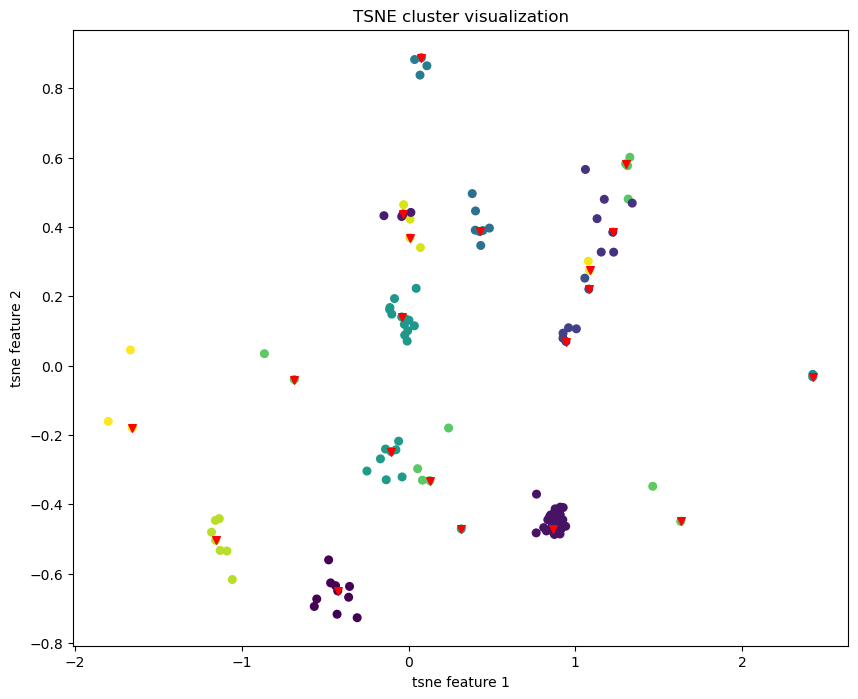

In [21]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import random

randClusters = random.sample(range(0, 999), 20)
print('Clusters sampled: ')
print(randClusters)

subsetDf = centers_df[centers_df['Cluster'].isin(randClusters)]
subsetSoap = subsetDf.drop(columns='Cluster').values

subsetFullDf = df_pca[df_pca['Cluster'].isin(randClusters)]
subsetFullSoap = subsetFullDf.drop(columns='Cluster').values

tsne = TSNE(n_components=2, perplexity=5)
tsneFeatures = tsne.fit_transform(subsetSoap)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(subsetFullSoap[:, 0], subsetFullSoap[:, 1], s=30, c=subsetFullDf['Cluster'], cmap='viridis')
ax.scatter(subsetSoap[:, 0], subsetSoap[:, 1], s=30, c='red', marker='v')

ax.set_xlabel('tsne feature 1')
ax.set_ylabel('tsne feature 2')
ax.set_title('TSNE cluster visualization')

# Tinkering

In [28]:
restype = set()
type = set()

for index, row in df.iterrows():
    restype.add(row['restype'])
    type.add(row['type'])

print(f'restypes: {restype}')
print(f'type: {type}\n')

restype_lig_group = {
    'TRP': set(), 
    'TYR': set(), 
    'PHE': set(), 
    'HIS': set()
}

for index, row in df.iterrows():
    restype_lig_group[row['restype']].add(row['type'])

print(f'restype_ligand interaction pairs: {restype_lig_group}\n')

restypes: {'PHE', 'TRP', 'TYR', 'HIS'}
type: {'T', 'P'}

restype_ligand interaction pairs: {'TRP': {'T', 'P'}, 'TYR': {'T', 'P'}, 'PHE': {'T', 'P'}, 'HIS': {'T', 'P'}}

